<a href="https://colab.research.google.com/github/IsaacFigNewton/DisCoFuzz/blob/dev/Testing_series_approximation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import and config

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf, logit, expit, erfc, erfcx
import tensorflow as tf

# Import from fourier_fuzzy_sets package
from fourier_fuzzy_sets.fuzzy_classes import FourierFuzzySet, SetOps, Mixture

In [2]:
L=10.0
# crashes for >=10^7 kernels
kernels_sweep = [10**i for i in range(0, 6)]
harmonics_sweep = [5, 10, 20, 40, 60, 80]
baseline_kernel_count = 10
baseline_harmonic_count = 20
x = np.linspace(0, 1, 2000)
dx = x[1] - x[0]

## FourierPMFTransformer

In [3]:
"""
Fourier Fuzzy GMM - build and evaluate a simple Gaussian Mixture Model
using the Fourier-series fuzzy set framework from:

  "Fourier Series Approximations of Likelihood-Based Fuzzy Sets"
   (Rudnick, 2026)

Refactored to use the fourier_fuzzy_sets package.
"""

'\nFourier Fuzzy GMM - build and evaluate a simple Gaussian Mixture Model\nusing the Fourier-series fuzzy set framework from:\n\n  "Fourier Series Approximations of Likelihood-Based Fuzzy Sets"\n   (Rudnick, 2026)\n\nRefactored to use the fourier_fuzzy_sets package.\n'

# Fuzzy Set Ops Demo

## Config

In [4]:
band_size = 30
# Use resolution matching x from cell 3
model = FourierFuzzySet(n=band_size, L=L, resolution=len(x))
ops = SetOps(n=band_size, L=L)
mixture = Mixture(model)

mu_f, sig_f = 0.5, 0.05
mu_g, sig_g = 0.7, 0.2

In [5]:
# Create component tensors for batch processing
components_f = tf.constant([[mu_f, sig_f]], dtype=tf.float32)
components_g = tf.constant([[mu_g, sig_g]], dtype=tf.float32)

cf = model.get_gaussian_harmonics_batch(components_f, rescale=False)[0]
cg = model.get_gaussian_harmonics_batch(components_g, rescale=False)[0]

In [6]:
# Evaluate on grid using batch evaluation
yf_batch = model.evaluate_batch(tf.expand_dims(cf, 0))[0]
yg_batch = model.evaluate_batch(tf.expand_dims(cg, 0))[0]

# Convert to numpy for plotting
yf = tf.math.real(yf_batch).numpy()
yg = tf.math.real(yg_batch).numpy()

In [7]:
%matplotlib inline

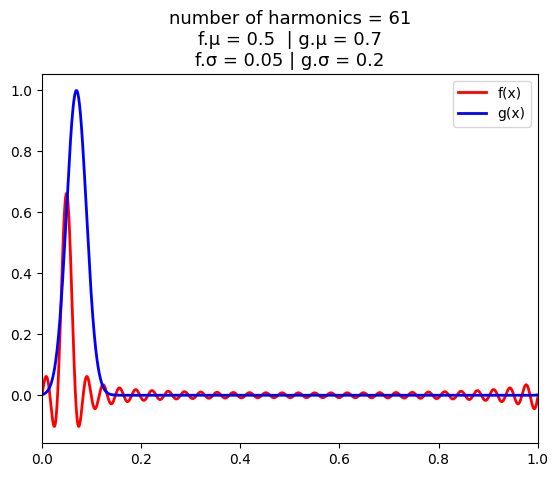

In [8]:
plt.plot(x, yf, label="f(x)", color="red", lw=2)
plt.plot(x, yg, label="g(x)", color="blue", lw=2)
plt.title(
    f"number of harmonics = {band_size*2+1}\n"
    f"f.μ = {mu_f}  | g.μ = {mu_g}\n"
    f"f.σ = {sig_f} | g.σ = {sig_g}",
    fontsize=13
)
plt.xlim(0, 1)
plt.legend()
plt.show()

## Set ops

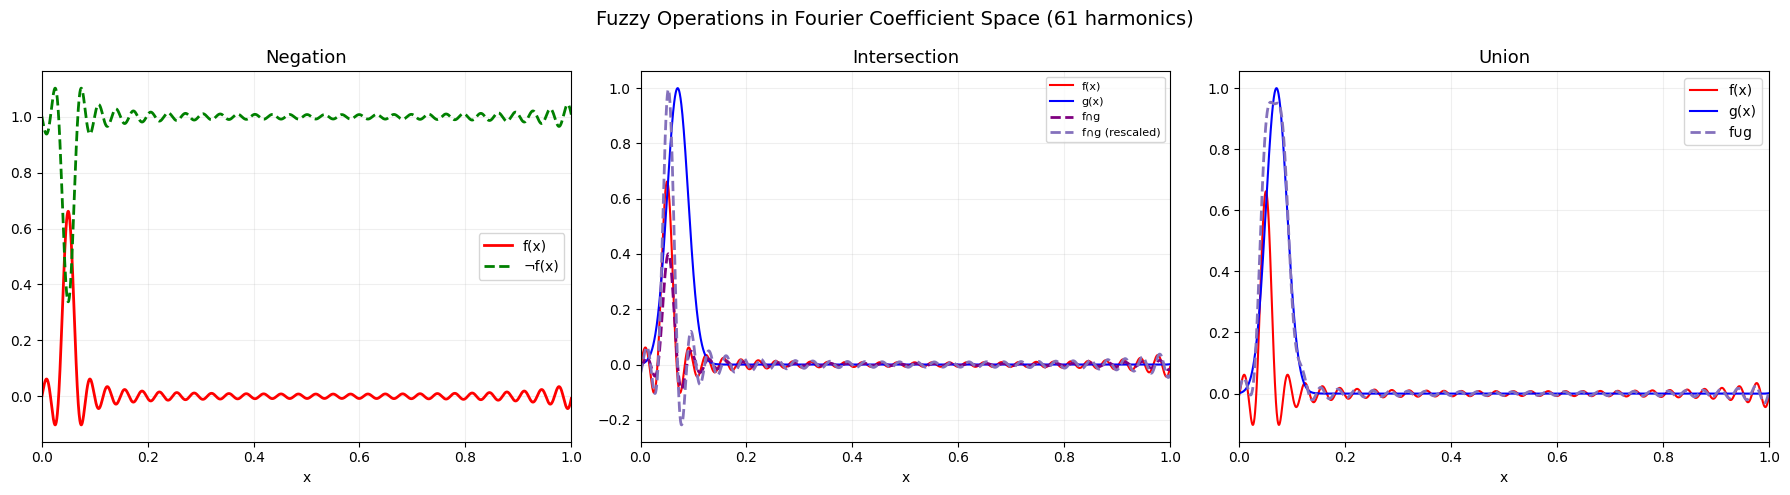

In [9]:
fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))

# Negation
cn_batch = ops.negation_batch(tf.expand_dims(cf, 0))
yn_batch = model.evaluate_batch(cn_batch)[0]
yn = tf.math.real(yn_batch).numpy()

axes2[0].plot(x, yf, label="f(x)", color="red", lw=2)
axes2[0].plot(x, yn, "--", label="¬f(x)", color="green", lw=2)
axes2[0].set_title("Negation", fontsize=13)
axes2[0].legend()
axes2[0].set_xlim(0, 1)

# Intersection
ci_batch = ops.intersect_batch(
    tf.expand_dims(cf, 0), 
    tf.expand_dims(cg, 0), 
    rescale=False
)
yi_batch = model.evaluate_batch(ci_batch)[0]
yi = tf.math.real(yi_batch).numpy()

ci_r_batch = ops.intersect_batch(
    tf.expand_dims(cf, 0), 
    tf.expand_dims(cg, 0), 
    rescale=True
)
yi_r_batch = model.evaluate_batch(ci_r_batch)[0]
yi_r = tf.math.real(yi_r_batch).numpy()

axes2[1].plot(x, yf, label="f(x)", color="red", lw=1.5)
axes2[1].plot(x, yg, label="g(x)", color="blue", lw=1.5)
axes2[1].plot(x, yi, "--", label="f∩g", color="purple", lw=2)
axes2[1].plot(x, yi_r, "--", label="f∩g (rescaled)", color="#8471BC", lw=2)
axes2[1].set_title("Intersection", fontsize=13)
axes2[1].legend(fontsize=8)
axes2[1].set_xlim(0, 1)

# Union
cu_batch = ops.union_batch(tf.expand_dims(cf, 0), tf.expand_dims(cg, 0))
yu_batch = model.evaluate_batch(cu_batch)[0]
yu = tf.math.real(yu_batch).numpy()

axes2[2].plot(x, yf, label="f(x)", color="red", lw=1.5)
axes2[2].plot(x, yg, label="g(x)", color="blue", lw=1.5)
axes2[2].plot(x, yu, "--", label="f∪g", color="#8471BC", lw=2)
axes2[2].set_title("Union", fontsize=13)
axes2[2].legend()
axes2[2].set_xlim(0, 1)

for a in axes2:
    a.set_xlabel("x")
    a.grid(True, alpha=0.2)

fig2.suptitle(f"Fuzzy Operations in Fourier Coefficient Space ({band_size*2+1} harmonics)",
              fontsize=14)
fig2.tight_layout()
# fig2.savefig("fuzzy_ops_demo.png", dpi=150, bbox_inches="tight")
# print("Saved: fuzzy_ops_demo.png")

# Case Study: Gaussian Mixture Model Scaling Comparison

## Helpers

### Ground-truth truncated Gaussian on [0, 1]

In [10]:
import numpy as np
from scipy.stats import norm

def trunc_normal_density(x, mu, sigma):
    """Vectorized truncated normal density on [0, 1]."""
    x = np.asarray(x)
    mu = np.asarray(mu)
    sigma = np.asarray(sigma)

    x_col = x[:, None]

    Z = norm.cdf(1, loc=mu, scale=sigma) - norm.cdf(0, loc=mu, scale=sigma)

    density = norm.pdf(x_col, loc=mu, scale=sigma) / Z

    return np.where((x_col >= 0) & (x_col <= 1), density, 0.0)


def analytic_mixture(x, components, weights):
    """Weighted sum of truncated Gaussians."""
    densities = trunc_normal_density(x, components[0], components[1])
    return np.sum(weights * densities, axis=1)

### Evaluation helpers

In [11]:
import numpy as np
import time

EPS = 1e-300

def normalize_density(y, dx, eps=EPS):
    """
    Ensure a numerically valid density:
    - clips negative / near-zero values
    - renormalizes so integral is approximately 1
    """
    y = np.asarray(y, dtype=float)
    y = np.clip(y, eps, None)
    z = np.sum(y) * dx
    if z <= 0 or not np.isfinite(z):
        raise ValueError("Density normalization failed.")
    return y / z


def avg_log_likelihood(y_density, dx, eps=EPS):
    """
    Grid-based expected log-likelihood under the same density.

    For a true sample-based log-likelihood, evaluate the density at held-out
    samples instead. This version is useful for comparing density quality
    on the benchmark grid.
    """
    y = normalize_density(y_density, dx, eps=eps)
    return np.sum(y * np.log(y)) * dx


def cross_log_likelihood(y_model, y_true, dx, eps=EPS):
    """
    Expected log-likelihood of the model density under the true density:
        E_{x ~ p_true}[log p_model(x)]
    """
    p = normalize_density(y_true, dx, eps=eps)
    q = normalize_density(y_model, dx, eps=eps)
    return np.sum(p * np.log(q)) * dx


def kl_divergence(y_true, y_model, dx, eps=EPS):
    """
    KL(p_true || p_model):
        integral p_true(x) log(p_true(x) / p_model(x)) dx
    """
    p = normalize_density(y_true, dx, eps=eps)
    q = normalize_density(y_model, dx, eps=eps)
    return np.sum(p * (np.log(p) - np.log(q))) * dx

## Evaluation config

In [12]:
rng = np.random.default_rng(42)

def make_gmm(n):
    """Generate a random k-component Gaussian mixture on [0, 1]."""
    means  = rng.uniform(0.05, 0.95, size=n)
    stds   = rng.uniform(0.005, 0.06, size=n)
    weights = rng.dirichlet(np.ones(n))[None, :]
    components = np.stack([means, stds], axis=1).T
    return components, weights

experiments = dict()
for n in kernels_sweep:
    comps, w = make_gmm(n)
    experiments[n] = (comps, w)

## Stress tests

### Harmonic stress tests

In [13]:
comps_test = experiments[baseline_kernel_count][0]
print(comps_test.shape)

wts_test = experiments[baseline_kernel_count][1]
print(wts_test.shape)

t0 = time.perf_counter()
y_true = analytic_mixture(x, comps_test, wts_test)
t_baseline = (time.perf_counter() - t0) / 200

y_true_eval = normalize_density(y_true, dx)

baseline_self_ll = avg_log_likelihood(y_true_eval, dx)

print(f"baseline additive GMM:\t{t_baseline*1000:6.2f} ms")
print(f"baseline avg log-likelihood:\t{baseline_self_ll:10.6f}")

harmonic_count_eval_dict = {
    "harmonic count": harmonics_sweep,
    "FFS time (ms)": [],
    "avg log-likelihood": [],
    "KL divergence": [],
}

# Convert components to TensorFlow format (transpose for batch processing)
comps_test_tf = tf.constant(comps_test.T, dtype=tf.float32)
wts_test_tf = tf.constant(wts_test[0], dtype=tf.float32)

for n in harmonics_sweep:
    m = FourierFuzzySet(n=n, L=L, resolution=len(x))
    o = SetOps(n=n, L=L)
    mix = Mixture(m)

    t0 = time.perf_counter()
    for _ in range(200):
        ca = mix.fourier_gmm(o, comps_test_tf, wts_test_tf)
        _ = m.evaluate_batch(tf.expand_dims(ca, 0))

    t_add = (time.perf_counter() - t0) / 200
    harmonic_count_eval_dict["FFS time (ms)"].append(t_add * 1000)

    ya_batch = m.evaluate_batch(tf.expand_dims(ca, 0))[0]
    ya_eval = normalize_density(ya_batch.numpy(), dx)

    ll_add = cross_log_likelihood(
        y_model=ya_eval,
        y_true=y_true_eval,
        dx=dx,
    )

    kl_add = kl_divergence(
        y_true=y_true_eval,
        y_model=ya_eval,
        dx=dx,
    )

    harmonic_count_eval_dict["avg log-likelihood"].append(ll_add)
    harmonic_count_eval_dict["KL divergence"].append(kl_add)

    print(
        f"  n:\t{n:3d}"
        f"  |  time:\t{t_add*1000:6.2f} ms"
        f"  |  avg LL:\t{ll_add:10.6f}"
        f"  |  KL:\t{kl_add:10.2e}"
    )

(2, 10)
(1, 10)
baseline additive GMM:	  0.02 ms
baseline avg log-likelihood:	  0.400165


C:\Users\igeek\AppData\Local\Temp\ipykernel_13528\2123922397.py:12: ComplexWarning: Casting complex values to real discards the imaginary part
  y = np.asarray(y, dtype=float)


  n:	  5  |  time:	  2.62 ms  |  avg LL:	-348.621064  |  KL:	  3.49e+02
  n:	 10  |  time:	  2.71 ms  |  avg LL:	-346.661312  |  KL:	  3.47e+02
  n:	 20  |  time:	  2.98 ms  |  avg LL:	-342.766926  |  KL:	  3.43e+02
  n:	 40  |  time:	  3.61 ms  |  avg LL:	-342.260964  |  KL:	  3.43e+02
  n:	 60  |  time:	  4.02 ms  |  avg LL:	-343.529029  |  KL:	  3.44e+02
  n:	 80  |  time:	  4.64 ms  |  avg LL:	-343.543204  |  KL:	  3.44e+02


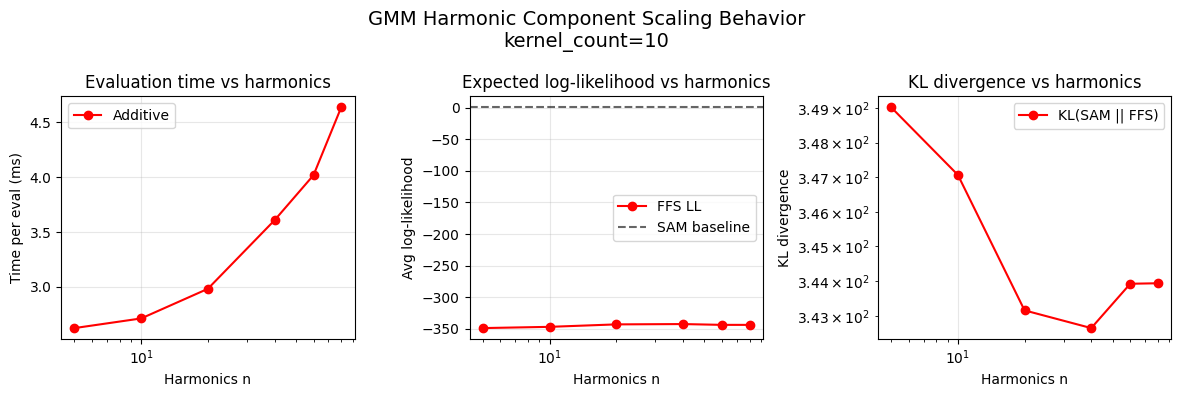

In [14]:
fig3, axes = plt.subplots(1, 3, figsize=(12, 4))
ax_t, ax_ll, ax_kl = axes.ravel()

ax_t.plot(
    harmonics_sweep,
    harmonic_count_eval_dict["FFS time (ms)"],
    "o-",
    color="red",
    label="Additive",
)
ax_t.set_xlabel("Harmonics n")
ax_t.set_xscale("log")
ax_t.set_ylabel("Time per eval (ms)")
ax_t.set_title("Evaluation time vs harmonics")
ax_t.legend()
ax_t.grid(True, alpha=0.3)


ax_ll.plot(
    harmonics_sweep,
    harmonic_count_eval_dict["avg log-likelihood"],
    "o-",
    color="red",
    label="FFS LL",
)
ax_ll.axhline(
    baseline_self_ll,
    linestyle="--",
    color="black",
    alpha=0.6,
    label="SAM baseline",
)
ax_ll.set_xlabel("Harmonics n")
ax_ll.set_xscale("log")
ax_ll.set_ylabel("Avg log-likelihood")
ax_ll.set_title("Expected log-likelihood vs harmonics")
ax_ll.legend()
ax_ll.grid(True, alpha=0.3)


ax_kl.semilogy(
    harmonics_sweep,
    harmonic_count_eval_dict["KL divergence"],
    "o-",
    color="red",
    label="KL(SAM || FFS)",
)
ax_kl.set_xlabel("Harmonics n")
ax_kl.set_xscale("log")
ax_kl.set_ylabel("KL divergence")
ax_kl.set_title("KL divergence vs harmonics")
ax_kl.legend()
ax_kl.grid(True, alpha=0.3)


fig3.suptitle(
    f"GMM Harmonic Component Scaling Behavior\n"
    f"kernel_count={baseline_kernel_count}",
    fontsize=14,
)

fig3.tight_layout()
# fig3.savefig("harmonic_timing_scaling.png", dpi=150, bbox_inches="tight")
# print("\nSaved: harmonic_timing_scaling.png")

### Kernel count stress tests

In [15]:
m = FourierFuzzySet(n=baseline_harmonic_count, L=L, resolution=len(x))
o = SetOps(n=baseline_harmonic_count, L=L)
mix = Mixture(m)

kernel_count_eval_dict = {
    "kernel count": kernels_sweep,
    "SAM time (ms)": [],
    "FFS time (ms)": [],
    "avg log-likelihood": [],
    "KL divergence": [],
}

for row, (n, (comps, wts)) in enumerate(experiments.items()):
    t0 = time.perf_counter()
    y_true = analytic_mixture(x, comps, wts)
    t_true = (time.perf_counter() - t0) / 200
    kernel_count_eval_dict["SAM time (ms)"].append(t_true * 1000)

    y_true_eval = normalize_density(y_true, dx)

    # Convert to TensorFlow format
    comps_tf = tf.constant(comps.T, dtype=tf.float32)
    wts_tf = tf.constant(wts[0], dtype=tf.float32)

    t0 = time.perf_counter()
    ca = mix.fourier_gmm(o, comps_tf, wts_tf)
    y_add_batch = m.evaluate_batch(tf.expand_dims(ca, 0))[0]
    t_add = (time.perf_counter() - t0) / 200
    kernel_count_eval_dict["FFS time (ms)"].append(t_add * 1000)

    y_add = tf.math.real(y_add_batch).numpy()
    y_add_eval = normalize_density(y_add, dx)

    ll_add = cross_log_likelihood(
        y_model=y_add_eval,
        y_true=y_true_eval,
        dx=dx,
    )

    kl_add = kl_divergence(
        y_true=y_true_eval,
        y_model=y_add_eval,
        dx=dx,
    )

    kernel_count_eval_dict["avg log-likelihood"].append(ll_add)
    kernel_count_eval_dict["KL divergence"].append(kl_add)

    print(
        f"\tn: {n:10.0e}\t|"
        f"\tSAM time: {t_true*1000:6.2f} ms\t|"
        f"\tFFS time: {t_add*1000:6.2f} ms\t|"
        f"\tavg LL: {ll_add:10.6f}\t|"
        f"\tKL: {kl_add:10.2e}"
    )

	n:      1e+00	|	SAM time:   0.00 ms	|	FFS time:   0.38 ms	|	avg LL: -348.134030	|	KL:   3.50e+02
	n:      1e+01	|	SAM time:   0.01 ms	|	FFS time:   0.02 ms	|	avg LL: -342.766926	|	KL:   3.43e+02
	n:      1e+02	|	SAM time:   0.06 ms	|	FFS time:   0.02 ms	|	avg LL: -320.572378	|	KL:   3.21e+02
	n:      1e+03	|	SAM time:   0.62 ms	|	FFS time:   0.09 ms	|	avg LL: -324.002185	|	KL:   3.24e+02
	n:      1e+04	|	SAM time:   6.40 ms	|	FFS time:   0.65 ms	|	avg LL: -329.841124	|	KL:   3.30e+02
	n:      1e+05	|	SAM time:  64.74 ms	|	FFS time:   6.34 ms	|	avg LL: -327.569412	|	KL:   3.28e+02


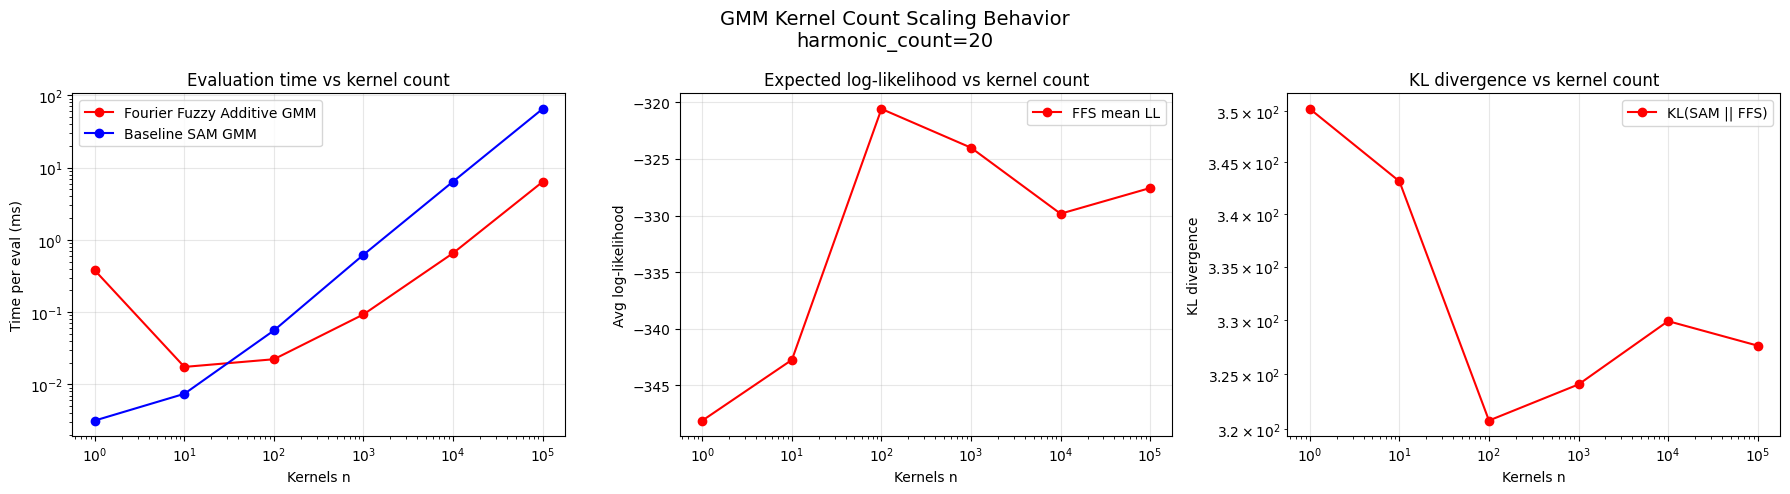

In [16]:
fig3, axes = plt.subplots(1, 3, figsize=(18, 5))
ax_t, ax_ll, ax_kl = axes.ravel()

ax_t.plot(
    kernels_sweep,
    kernel_count_eval_dict["FFS time (ms)"],
    "o-",
    color="red",
    label="Fourier Fuzzy Additive GMM",
)
ax_t.plot(
    kernels_sweep,
    kernel_count_eval_dict["SAM time (ms)"],
    "o-",
    color="blue",
    label="Baseline SAM GMM",
)
ax_t.set_xlabel("Kernels n")
ax_t.set_xscale("log")
ax_t.set_ylabel("Time per eval (ms)")
ax_t.set_yscale("log")
ax_t.set_title("Evaluation time vs kernel count")
ax_t.legend()
ax_t.grid(True, alpha=0.3)


ax_ll.plot(
    kernels_sweep,
    kernel_count_eval_dict["avg log-likelihood"],
    "o-",
    color="red",
    label="FFS mean LL",
)
ax_ll.set_xlabel("Kernels n")
ax_ll.set_xscale("log")
ax_ll.set_ylabel("Avg log-likelihood")
ax_ll.set_title("Expected log-likelihood vs kernel count")
ax_ll.legend()
ax_ll.grid(True, alpha=0.3)


ax_kl.semilogy(
    kernels_sweep,
    kernel_count_eval_dict["KL divergence"],
    "o-",
    color="red",
    label="KL(SAM || FFS)",
)
ax_kl.set_xlabel("Kernels n")
ax_kl.set_xscale("log")
ax_kl.set_ylabel("KL divergence")
ax_kl.set_title("KL divergence vs kernel count")
ax_kl.legend()
ax_kl.grid(True, alpha=0.3)


fig3.suptitle(
    f"GMM Kernel Count Scaling Behavior\n"
    f"harmonic_count={baseline_harmonic_count}",
    fontsize=14,
)

fig3.tight_layout()
# fig3.savefig("kernel_timing_scaling.png", dpi=150, bbox_inches="tight")
# print("\nSaved: kernel_timing_scaling.png")

# FFS v SAM reconstructions

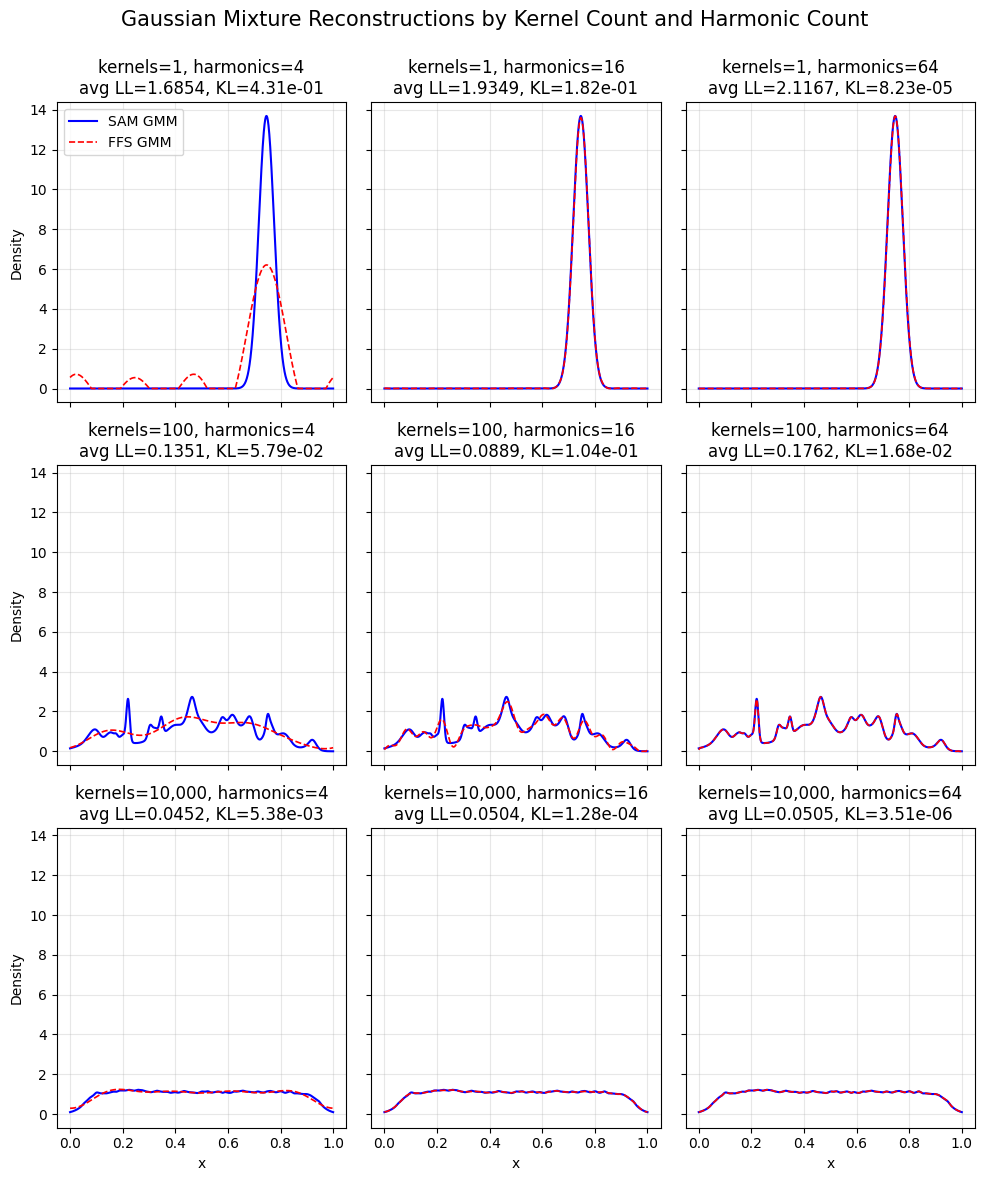

In [17]:
kernel_counts = [1, 100, 10000]
harmonic_counts = [4, 16, 64]

fig, axes = plt.subplots(
    len(kernel_counts),
    len(harmonic_counts),
    figsize=(10, 12),
    sharex=True,
    sharey=True
)

for i, kernel_count in enumerate(kernel_counts):
    comps, wts = experiments[kernel_count]

    y_true = analytic_mixture(x, comps, wts)
    y_true_eval = normalize_density(y_true, dx)

    # Convert to TensorFlow format
    comps_tf = tf.constant(comps.T, dtype=tf.float32)
    wts_tf = tf.constant(wts[0], dtype=tf.float32)

    for j, harmonic_count in enumerate(harmonic_counts):
        ax = axes[i, j]

        m = FourierFuzzySet(n=harmonic_count, L=1.0, resolution=len(x))
        o = SetOps(n=harmonic_count, L=1.0, dtype=tf.float32)
        mix = Mixture(m)

        ca = mix.fourier_gmm(o, comps_tf, wts_tf)
        y_ffs_batch = m.evaluate_batch(tf.expand_dims(ca, 0))[0]
        y_ffs = tf.math.real(y_ffs_batch).numpy()
        y_ffs_eval = normalize_density(y_ffs, dx)

        ll = cross_log_likelihood(
            y_model=y_ffs_eval,
            y_true=y_true_eval,
            dx=dx,
        )

        kl = kl_divergence(
            y_true=y_true_eval,
            y_model=y_ffs_eval,
            dx=dx,
        )

        ax.plot(
            x,
            y_true_eval,
            color="blue",
            linewidth=1.5,
            label="SAM GMM",
        )
        ax.plot(
            x,
            y_ffs_eval,
            color="red",
            linewidth=1.2,
            linestyle="--",
            label="FFS GMM",
        )

        ax.set_title(
            f"kernels={kernel_count:,.0f}, harmonics={harmonic_count}\n"
            f"avg LL={ll:.4f}, KL={kl:.2e}"
        )
        ax.grid(True, alpha=0.3)

        if i == len(kernel_counts) - 1:
            ax.set_xlabel("x")

        if j == 0:
            ax.set_ylabel("Density")

        if i == 0 and j == 0:
            ax.legend()

fig.suptitle(
    "Gaussian Mixture Reconstructions by Kernel Count and Harmonic Count\n",
    fontsize=15,
)

fig.tight_layout()
# fig.savefig("gmm_kernel_harmonic_grid.png", dpi=150, bbox_inches="tight")
# print("\nSaved: gmm_kernel_harmonic_grid.png")